Complete the exercises below For **Assignment #11**.

For this assignment we'll use the [California Housing Data](https://inria.github.io/scikit-learn-mooc/python_scripts/datasets_california_housing.html).

This data is available in the [Scikit-Learn](https://scikit-learn.org/stable/index.html) Python module.

To retrieve the data,
1. open a new Python notebook, and,
2. run the following code.

```python
from sklearn.datasets import fetch_california_housing

california_housing = fetch_california_housing(as_frame=True)

(
    california_housing.data
    .assign(MedianHouseValue=california_housing.target)
    .to_csv('california-housing.csv', index=False)
)
```

This will produce a new file called `california-housing.csv` that we'll import in this notebook.

Back in the Python notebook, you can use the following snippet to get a description of the dataset.

```python
print(california_housing.DESCR)
```


In [1]:
from sklearn.datasets import fetch_california_housing

california_housing = fetch_california_housing(as_frame=True)

(
    california_housing.data
    .assign(MedianHouseValue=california_housing.target)
    .to_csv('california-housing.csv', index=False)
)

In [2]:
print(california_housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

Import the libraries we'll use.

In [3]:
import json
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

Run the following cell to read in our data.

In [4]:
housing = pd.read_csv('california-housing.csv')

housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedianHouseValue
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Let's build a random forest model to predict `MedianHouseValue`.

1. Create a `RandomForestRegressor` from Scikit-Learn with `oob_score=True`.
2. Fit the model using `MedianHouseValue` as the response variable and all other columns as predictors.

In [5]:
X = housing.drop(columns='MedianHouseValue')
y = housing['MedianHouseValue']

rf = RandomForestRegressor(n_estimators=500, oob_score=True, n_jobs=-1, random_state=42)
rf.fit(X, y)

RandomForestRegressor(n_estimators=500, n_jobs=-1, oob_score=True,
                      random_state=42)

❓ What is the OOB error for this model?

**Answer:**
The OOB error is the out-of-bag mean squared error printed by the cell below (OOB MSE), with its square root (OOB RMSE) giving the typical prediction error in units of $100,000. The out-of-bag R² is printed too.

In [7]:
# oob_score_ is the out-of-bag R^2; the OOB error is the MSE of the out-of-bag predictions
oob_mse = np.mean((y - rf.oob_prediction_) ** 2)

print('OOB R^2: ', rf.oob_score_)
print('OOB MSE: ', oob_mse)
print('OOB RMSE:', np.sqrt(oob_mse), '(in units of $100,000)')

OOB R^2:  0.8175078415205737
OOB MSE:  0.24299748838585686
OOB RMSE: 0.49294775421524833 (in units of $100,000)


Plot the feature importances using the random forest's `feature_importances_` attribute.

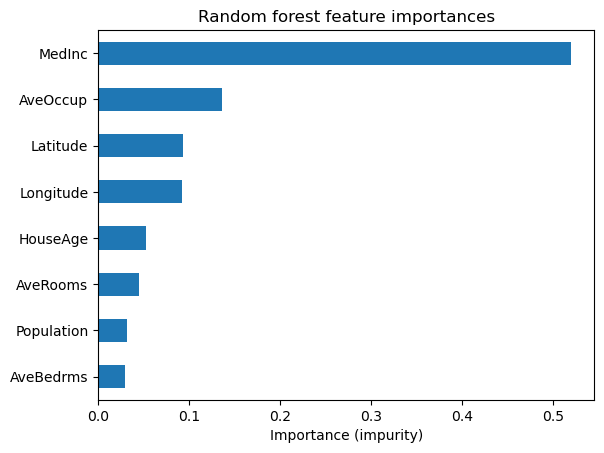

In [8]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

importances.plot.barh()
plt.xlabel('Importance (impurity)')
plt.title('Random forest feature importances')
plt.show()

It looks like `Latitude` and `Longitude` are important for predicting home value. Let's explore those variables.

In Python we'll draw the state outline with `matplotlib`, using a GeoJSON file of US state boundaries, so there is nothing extra to install.

Load the California outline.

In [9]:
url = 'https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json'

with urllib.request.urlopen(url) as f:
    states = json.load(f)

ca = next(ft for ft in states['features'] if ft['properties']['name'] == 'California')['geometry']

# Polygon -> list of one polygon; MultiPolygon -> list of polygons
polygons = [ca['coordinates']] if ca['type'] == 'Polygon' else ca['coordinates']

Plot `Latitude` and `Longitude` from the `housing` dataset on a map of California, coloring points by `MedianHouseValue`. [Here is an example for reference](https://raw.githubusercontent.com/UNC-DATA-730/a10/main/example.png).

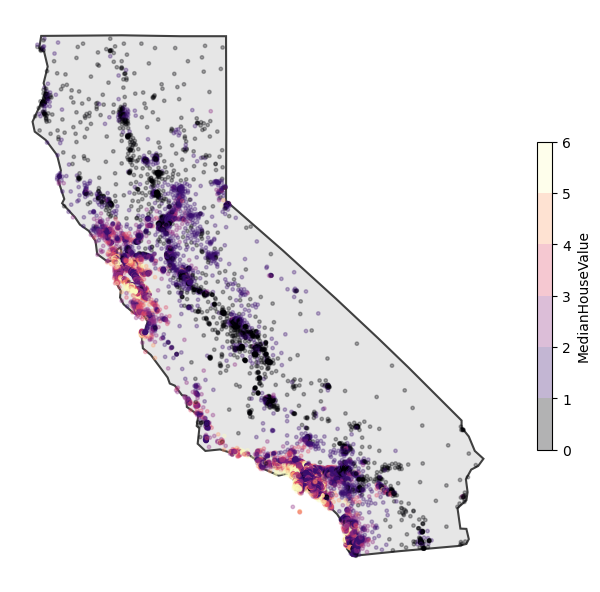

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))

# California outline
for poly in polygons:
    outer = np.array(poly[0])
    ax.fill(outer[:, 0], outer[:, 1], facecolor='0.9', edgecolor='0.25', linewidth=1.5)

# Housing points colored by MedianHouseValue (binned, like the example)
cmap = plt.get_cmap('magma', 6)
norm = plt.matplotlib.colors.BoundaryNorm(np.arange(0, 7), cmap.N)
sc = ax.scatter(housing['Longitude'], housing['Latitude'], c=housing['MedianHouseValue'],
                cmap=cmap, norm=norm, s=6, alpha=0.3)

ax.set_aspect(1 / np.cos(np.radians(37)))  # roughly equal-distance scaling at CA's latitude
ax.axis('off')
fig.colorbar(sc, ax=ax, shrink=0.5, label='MedianHouseValue')
plt.show()